# E07 · Shape-focused input, with and without topological features (variants a, b)

`07_topological_features` showed that the *shapes* in an image differ much less between EuroSAT and Kaggle than the
band values (EuroSAT-vs-Kaggle AUC 0.91 for topological features vs 0.999 for spectral statistics). It also showed that
removing all brightness information goes too far: water became unrecognisable. This notebook makes the CNN rely more on
shape, keeping a small path for brightness.

Same setup as `E06c` (EfficientNet-B0 features, 12 bands, `hist_split`, contrast augmentation, the same round-2
pseudo-labels used 2×, AdaBN balanced at the end). **The change is the model**, `efficientnet_b0_shape`
(`ShapeFocusedNet` in `src/models.py`):

| Part | What it does |
|---|---|
| Per-image standardisation | each band of each image is shifted/scaled to mean 0, spread 1 *within the image* before EfficientNet; global brightness, offset and contrast differences disappear, only patterns remain |
| Statistics branch | the removed per-band means and log-spreads (24 values) → small MLP (64) → joined with the CNN features before the classifier |
| Branch dropout | the statistics are switched off for 30% of the training images, so the model must recognise classes from the patterns |
| Topology branch (**E07b** only) | 160 topological features per image (NIR, brightness, edges; NDVI left out, it shifted most) → MLP 160 → 128 → 64, as in Sharma (2025, arXiv:2507.10381) |

| Variant | Parameters |
|---|---|
| **E07a** shape-focused input | 4,029,350 |
| **E07b** + topology branch | 4,058,854 |

The side branches have no BatchNorm, so AdaBN only adapts the CNN. Section 4 also builds the **ensemble** of each
variant with E06c (averaged probabilities): a shape-focused model should make different mistakes than E06c.

The topological features are loaded from `data/cache/topo_features.npz`; run `notebooks/data/07_topological_features`
first if it is missing. Pseudo-labels: selected as in `E06c` (same `find_run` note applies; `CHECK_RUN` = `LABEL_RUN`).

**Train or load.** `LOAD_RUNS` points every variant to its saved run: the notebook loads the weights and
recomputes all results and submission files without training. Set one entry to `None` to train that variant again
(about 25 minutes each on an M4 GPU; creates new run folders).

## 1 · Setup and data

In [1]:
import json
import sys
from dataclasses import asdict, replace
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.insert(0, str(ROOT))
from src.data import CLASSES, PROJECT_ROOT, TEST_BANDS
from src.experiment import (add_pseudo_labels, adabn_balanced, class_mix, compare_variants, find_run,
                            finish_run, kaggle_monitor, load_experiment_data, load_saved_model,
                            plot_class_mix, plot_variant_curves, pseudo_label_summary,
                            pseudo_labels_from_run, pseudo_labels_from_table, view_agreement)
from src.models import MEDIUM_TRACK_LIMIT, build_model
from src.plot_style import apply_style
from src.training import (Normalizer, TrainConfig, adapt_batchnorm, fit, load_run, new_run_dir,
                          predict_proba, predict_views, write_submission)
from src.utils import describe_device, get_device, seed_everything
from src.data import CACHE_DIR, load_split
from src.topology import feature_names
apply_style()

# ---- Experiment settings ---------------------------------------------------------------
NOTEBOOK = "E07_shape_input"
LOAD_RUNS = {   # saved runs; None = train this variant again
    "E07a": "runs/2026-10-13_1809_shape_pl_r2_x2_contrast_aug_hist_split_effb0",
    "E07b": "runs/2026-10-13_1826_shape_topo_pl_r2_x2_contrast_aug_hist_split_effb0",
}
LOAD_ENSEMBLES = {   # saved ensemble folders (E06c + variant); None = create new folders
    "E07a": "runs/2026-10-13_1810_ensemble_e10_shape_pl_r2_x2_contrast_aug_hist_split_effb0",
    "E07b": "runs/2026-10-13_1828_ensemble_e10_shape_topo_pl_r2_x2_contrast_aug_hist_split_effb0",
}
REFERENCE = "adabn_balanced_pseudo_label_r2_x2_contrast_aug_hist_split_effb0"   # E06c + AdaBN, 71.50%
# Pseudo-labels as in E06c
LABEL_RUN = "adabn_balanced_pseudo_label_contrast_aug_hist_split_effb0"   # E06a + AdaBN
CHECK_RUN = LABEL_RUN    # reproduces the runs (see E06)
PL_PER_CLASS, PL_REPEAT = 250, 2
TOPO_EXCLUDE = ("ndvi",)   # topological feature groups left out in E07b
MODEL = "efficientnet_b0_shape"
BANDS = list(TEST_BANDS)
SEED = 42
cfg = TrainConfig(epochs=20, batch_size=128, lr=1e-3, weight_decay=1e-4,
                  label_smoothing=0.1, patience=5, augment=True,
                  photometric={"contrast": (0.9, 1.5), "band_contrast": (0.9, 1.15),
                               "brightness": (0.93, 1.07), "p": 0.8})   # as in E04
# -----------------------------------------------------------------------------------------

seed_everything(SEED)
device = get_device()              # CUDA > Apple GPU (MPS) > CPU
print("Device:", describe_device(device))
results = {}                        # variant -> RunResult, compared at the end

data = load_experiment_data(BANDS, ["hist_split"], device)
print(data.summary())
pl_table, pl_idx = pseudo_labels_from_run(LABEL_RUN, CHECK_RUN, PL_PER_CLASS, data, device)
tr_images, tr_labels, rep_idx = add_pseudo_labels(data, pl_table, pl_idx, repeat=PL_REPEAT)


def train_or_load(variant, model_kwargs, tr_extra=None, va_extra=None, kg_extra=None):
    if LOAD_RUNS[variant]:
        model, normalizer, history = load_saved_model(LOAD_RUNS[variant], device)
        return model, normalizer, history, None
    seed_everything(SEED)
    normalizer = Normalizer.fit(data.X_tr)
    model = build_model(MODEL, bands=BANDS, pretrained=True, **model_kwargs).to(device)
    if tr_extra is not None:
        model.set_topo_stats(tr_extra[:len(data.tr_images)])   # EuroSAT training images only
    history, best_state = fit(model, tr_images, tr_labels, data.va_images, data.va_labels, normalizer, cfg,
                              monitor=kaggle_monitor(data, normalizer, va_extra, kg_extra),
                              train_extra=tr_extra, val_extra=va_extra)
    return model, normalizer, history, best_state


def base_config(variant, run_name, description, model_kwargs):
    return {"run_name": run_name, "description": description, "notebook": NOTEBOOK, "variant": variant,
            "model": MODEL, "model_kwargs": model_kwargs, "bands": BANDS, "corrections": ["hist_split"],
            "train": asdict(cfg), "split": "split_seed42",
            "pseudo_labels": {"label_run": LABEL_RUN, "check_run": CHECK_RUN, "per_class": PL_PER_CLASS,
                              "repeat": PL_REPEAT, "n_images": int(len(pl_idx))}}

Device: Apple GPU (MPS)


train 18,900  val 4,050  internal test 4,050  Kaggle test 4,232


Pseudo-labelled Kaggle images: 2,314 of 4,232, used 2x (19.7% of the training set, 23,528 images)


## 2 · E07a · Shape-focused input

In [2]:
model, normalizer, history, best_state = train_or_load("E07a", {})
results["E07a"] = finish_run(model, normalizer, history, best_state, data, variant="E07a", load_run=LOAD_RUNS["E07a"],
    device=device, seed=SEED, param_limit=MEDIUM_TRACK_LIMIT,
    config=base_config("E07a", "shape_pl_r2_x2_contrast_aug_hist_split_effb0",
                       "shape-focused input (per-image standardisation + statistics branch) + E06c setup", {}))

Loaded runs/2026-10-13_1809_shape_pl_r2_x2_contrast_aug_hist_split_effb0 (20 epochs): no training


E07a: internal test 98.17% · Kaggle confidence 85.5% (with AdaBN 82.9%) · 4,029,350 parameters
  run folders: runs/2026-10-13_1809_shape_pl_r2_x2_contrast_aug_hist_split_effb0, runs/2026-10-13_1810_adabn_balanced_shape_pl_r2_x2_contrast_aug_hist_split_effb0


## 3 · E07b · Shape-focused input + topological features

The features don't change under rotations/flips, so the precomputed values stay valid for the augmented and TTA views.
They are standardised with the EuroSAT training statistics, stored with the weights.

In [3]:
cache = np.load(CACHE_DIR / "topo_features.npz")
keep = np.array([not n.startswith(TOPO_EXCLUDE) for n in feature_names()])
part = load_split()["split"].values
to_dev = lambda a: torch.from_numpy(np.ascontiguousarray(a, dtype=np.float32)).to(device)
T_eu, kg_extra = cache["eurosat"][:, keep], to_dev(cache["kaggle"][:, keep])
tr_extra = torch.cat([to_dev(T_eu[part == "train"]), kg_extra[rep_idx]])
va_extra, te_extra = to_dev(T_eu[part == "val"]), to_dev(T_eu[part == "test"])
assert len(tr_extra) == len(tr_images) and len(va_extra) == len(data.va_images)
print(f"Topological features per image: {keep.sum()} (left out: {', '.join(TOPO_EXCLUDE)})")

topo_kwargs = {"n_topo": int(keep.sum())}
model, normalizer, history, best_state = train_or_load("E07b", topo_kwargs, tr_extra, va_extra, kg_extra)
results["E07b"] = finish_run(model, normalizer, history, best_state, data, variant="E07b", load_run=LOAD_RUNS["E07b"],
    device=device, seed=SEED, param_limit=MEDIUM_TRACK_LIMIT, te_extra=te_extra, kg_extra=kg_extra,
    config=base_config("E07b", "shape_topo_pl_r2_x2_contrast_aug_hist_split_effb0",
                       "shape-focused input + topology branch + E06c setup", topo_kwargs))

Topological features per image: 160 (left out: ndvi)


Loaded runs/2026-10-13_1826_shape_topo_pl_r2_x2_contrast_aug_hist_split_effb0 (12 epochs): no training


E07b: internal test 97.53% · Kaggle confidence 84.5% (with AdaBN 81.1%) · 4,058,854 parameters
  run folders: runs/2026-10-13_1826_shape_topo_pl_r2_x2_contrast_aug_hist_split_effb0, runs/2026-10-13_1827_adabn_balanced_shape_topo_pl_r2_x2_contrast_aug_hist_split_effb0


## 4 · Ensembles with E06c and comparison

Ensemble = average of the TTA probabilities of E06c + AdaBN and the variant + AdaBN (two models, about 8M parameters).

In [4]:
ref_model, ref_norm, _ = load_run(find_run(REFERENCE), device)
views_ref = predict_views(ref_model, data.kg_images, ref_norm)
prob_ref = views_ref.mean(0)
del ref_model

summary = compare_variants(results, reference=prob_ref, reference_name="E06c")
for k, r in results.items():
    views_ens = (views_ref + r.views_ada) / 2
    prob_ens = views_ens.mean(0)
    if LOAD_ENSEMBLES[k]:
        ens_dir = PROJECT_ROOT / LOAD_ENSEMBLES[k]
    else:
        ens_dir = new_run_dir(f"ensemble_e06c_{r.run_dir.name.split('_', 2)[-1]}")
        (ens_dir / "config.json").write_text(json.dumps({
            "run_name": ens_dir.name, "notebook": NOTEBOOK, "variant": k, "method": "ensemble (mean of TTA probabilities)",
            "description": f"E06c + AdaBN averaged with {r.description} + AdaBN",
            "members": [str(find_run(REFERENCE).relative_to(PROJECT_ROOT)), str(r.ada_dir.relative_to(PROJECT_ROOT))]}, indent=2))
        (ens_dir / "metrics.json").write_text(json.dumps({
            "kaggle_mean_confidence": float(prob_ens.max(1).mean()), "kaggle_view_agreement": view_agreement(views_ens),
            "kaggle_predicted_mix_pct": class_mix(prob_ens).round(2).to_dict(), "kaggle_public_score": None}, indent=2))
    write_submission(prob_ens, data.test_ids, ens_dir / "submission.csv")
    score = json.loads((ens_dir / "metrics.json").read_text()).get("kaggle_public_score")
    summary.loc[f"E06c + {k}"] = pd.Series({"description": "ensemble", "confidence (%)": prob_ens.max(1).mean() * 100,
                                  "view agreement (%)": view_agreement(views_ens) * 100,
                                  "same class as E06c (%)": (prob_ens.argmax(1) == prob_ref.argmax(1)).mean() * 100,
                                  "Kaggle public (%)": None if score is None else score * 100})
uncertain = prob_ref.max(1) < 0.6
for k, r in results.items():
    summary.loc[k, "differs on E06c-uncertain (%)"] = (r.prob_ada.argmax(1) != prob_ref.argmax(1))[uncertain].mean() * 100
summary.round(2)

,description,internal test (%),confidence (%),view agreement (%),same class as E06c (%),Kaggle public (%),differs on E06c-uncertain (%)
E07a,shape-focused input (per-image standardisation...,98.17284,82.938019,84.924386,90.477316,70.238,51.66
E07b,shape-focused input + topology branch + E06c s...,97.530864,81.111755,81.309074,89.319471,None,52.55
E06c + E07a,ensemble,NaN,81.094109,86.720227,94.754253,70.987,NaN
E06c + E07b,ensemble,NaN,79.992973,85.562382,94.990548,None,NaN


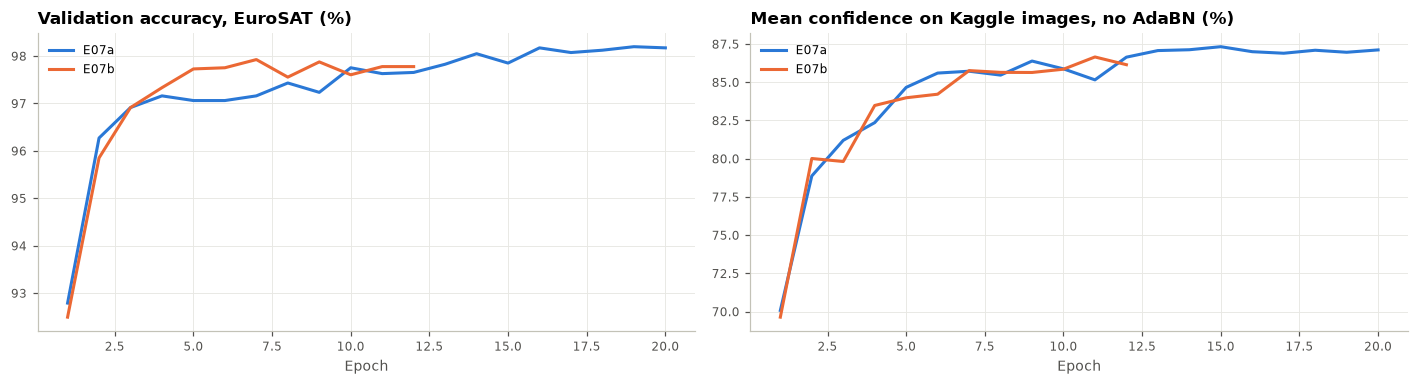

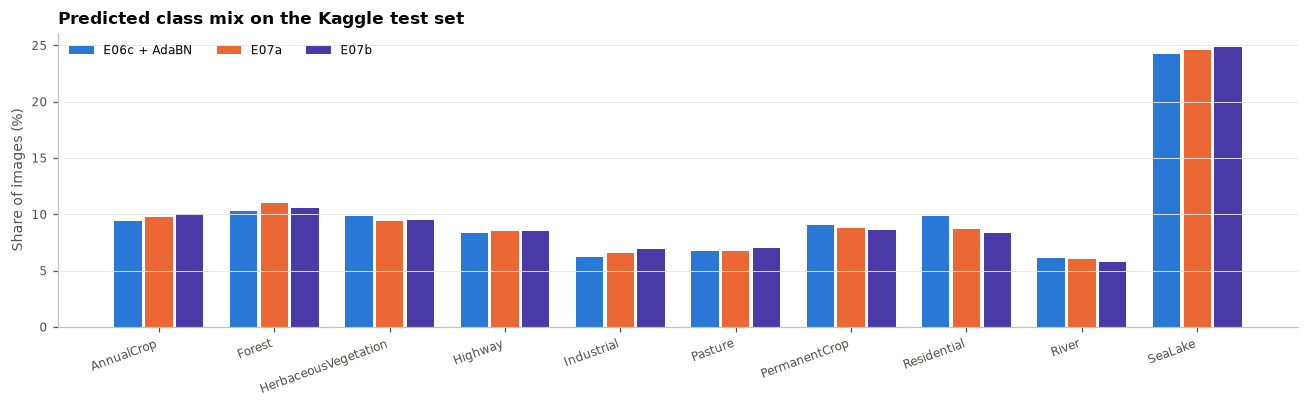

In [5]:
plot_variant_curves(results)
plot_class_mix(pd.DataFrame({"E06c + AdaBN": class_mix(prob_ref), **{k: class_mix(r.prob_ada) for k, r in results.items()}}))

## 5 · Conclusion

| | E06c + AdaBN | E07a + AdaBN | E07b + AdaBN | Ensemble E06c + E07a |
|---|---|---|---|---|
| Internal test (EuroSAT) | 98.94% | 98.17% | 97.53% | – |
| Confidence on Kaggle | 81.6% | 82.9% | 81.1% | 81.1% |
| View agreement | 84.2% | 84.9% | 81.3% | 86.7% |
| **Kaggle public** | **71.50%** | 70.24% | not submitted | 70.99% |

- **The shape-focused input costs 0.8 points on EuroSAT and 1.3 points on Kaggle.** Removing the absolute brightness
  from the main path loses information that is still useful on the Kaggle images. The statistics branch with 30%
  dropout doesn't fully make up for it.
- **The label-free measures were misleading here:** E07a was slightly more confident and more stable than E06c on
  Kaggle, but less accurate. Confidence and view agreement compare models of the *same* kind well (E06a → E06c), but not
  models with different inputs.
- **The ensemble with E06c (70.99%) is also below E06c alone.** E07a changes about half of E06c's uncertain images, but
  more often for the worse.
- **The topology branch makes everything slightly worse** (EuroSAT 97.53%, training stopped early after 12 epochs); not
  submitted. Together with `07_topological_features`: topology is a useful way to *show* that shapes transfer better
  than band values, but adds no information the CNN doesn't already extract.

**Lesson:** after `hist_split`, contrast augmentation, AdaBN and pseudo-labels, the remaining gap is not mainly a
brightness/offset problem any more; removing brightness information from the input doesn't help.